# LAB 1

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
from sklearn.preprocessing import LabelBinarizer
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize,sent_tokenize
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Unzipping corpora/wordnet.zip.


True

In [4]:
#loading The Dataset:

fake = pd.read_csv('/content/drive/MyDrive/sem2/eng/lab1/Fake.csv', delimiter = ',')
true = pd.read_csv('/content/drive/MyDrive/sem2/eng/lab1/True.csv', delimiter = ',')


In [5]:
#observing the top 5 rows of fake data:

fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [6]:
#observing the top 5 rows of true data:
true.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [7]:
#add extra column target
fake['target'] = 0
true['target'] = 1
#merge data
df = pd.DataFrame()
df = true.append(fake)


In [8]:
#observing the top 5 rows of all data:
df.head()

,title,text,subject,date,target
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [9]:
#Checking the shape of loaded data frames:
print(df.shape)


(44898, 5)


In [10]:
#Exploring the data:
df.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 44898 entries, 0 to 23480
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   target   44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 2.1+ MB


In [11]:
from sklearn.utils import shuffle
# Shuffle the data
df = shuffle(df).reset_index(drop=True)
df.head()


,title,text,subject,date,target
0,‘I’m Very Angry’: Dems ‘Outraged’ With Comey ...,FBI director James Comey on Friday and other I...,News,"January 13, 2017",0
1,China's Xi urges France to help restart talks ...,BEIJING (Reuters) - Chinese President Xi Jinpi...,worldnews,"September 8, 2017",1
2,Trump calls Russia reports 'fake news - a tota...,"(Reuters) - President-elect Donald Trump, in a...",politicsNews,"January 11, 2017",1
3,(VIDEO) JUDGE NAPOLITANO FILLS US IN ON ORDER ...,,politics,"May 20, 2015",0
4,SHUT IT DOWN! JUDICIAL WATCH PRES Calls Out Bi...,Are there any Trump donors on the team? GREAT...,politics,"Jul 3, 2017",0


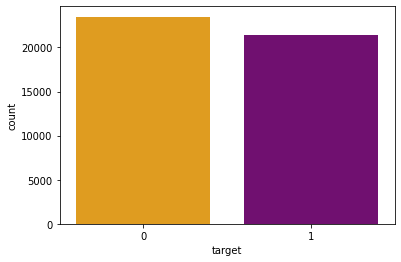

In [12]:
#This method shows the count of observations in each category
sns.countplot(x='target',data=df,palette=['orange','purple'])


In [13]:
#check the null values in the sample by summing null values
df.isnull().sum()


title      0
text       0
subject    0
date       0
target     0
dtype: int64

In [14]:
#check the types of columns
df.dtypes


title      object
text       object
subject    object
date       object
target      int64
dtype: object

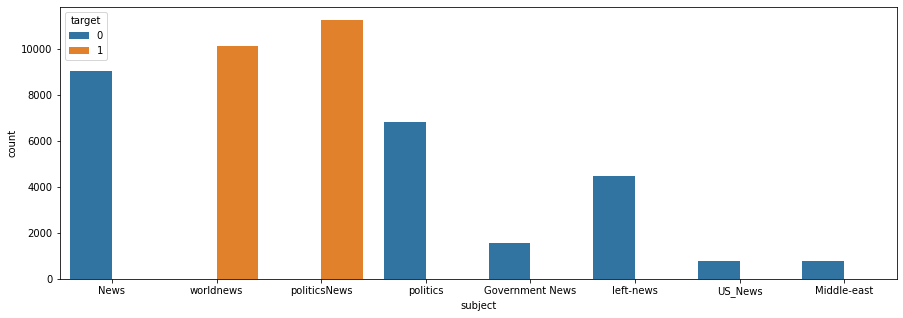

In [15]:
plt.figure(figsize=(15,5))
sns.countplot(x='subject',data=df,hue='target')

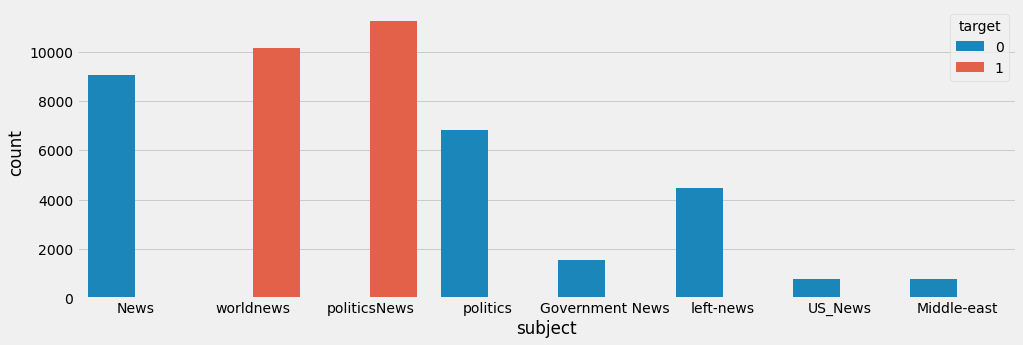

In [16]:
# there are shown the dependence between the the data by topics
plt.style.use('fivethirtyeight')
plt.figure(figsize=(15,5))
sns.countplot(x='subject',data=df,hue='target')

Task 1

Besides the default style, matplotlib comes with several built-in styles that we can use readily. For example, 'fivethirtyeight' is one of this. we can see that this one has a different background color, it has grid lines, there are no spines whatsoever, the weight and the font size of the major tick labels are different.

Task 2

As you can see the most popular subject in our data is 'politicsNews' and 'worldnews' and than a little bit less 'news'. 


In [17]:
#Combine text and title columns:
df['text']=df['text']+" "+df['title']


In [18]:
#Delete insignificant columns from the dataframe:
df.drop(['title','subject','date'],axis=1,inplace=True)
df.head()


,text,target
0,FBI director James Comey on Friday and other I...,0
1,BEIJING (Reuters) - Chinese President Xi Jinpi...,1
2,"(Reuters) - President-elect Donald Trump, in a...",1
3,(VIDEO) JUDGE NAPOLITANO FILLS US IN ON ORDE...,0
4,Are there any Trump donors on the team? GREAT...,0


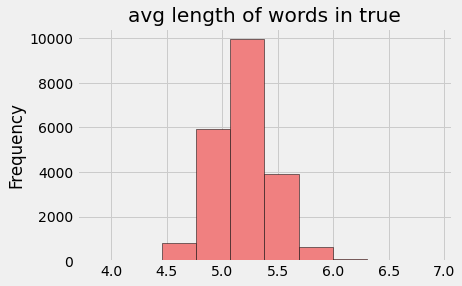

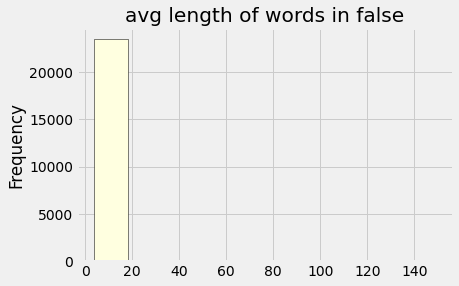

In [19]:
#Count and plot average length of words in real & fake news.
avg_len_word=df[df['target']==1].text.str.split().map(lambda
x:np.mean([len(word) for word in x]))
avg_len_word.plot(kind='hist',edgecolor='black',color='lightcoral',title='avg length of words in true')
plt.show()
avg_len_word=df[df['target']==0].text.str.split().map(lambda
x:np.mean([len(word) for word in x]))
avg_len_word.plot(kind='hist',edgecolor='black',color='lightyellow',title='avg length of words in false')
plt.show()


Task 3

As we can see the frequency of words in fake news more than 20000 and their lenghth less then 20.

On the other one in true news the most frequency of words less than 10000 and the avarage of length of words is distributed more than in fake news.

In [20]:
from collections import Counter
# add a column ‘temp_list’ with separate words to dataframe
df['temp_list']=df['text'].apply(lambda x: str(x).split())
# count the frequency of words occurrence 
top=Counter([word for li in df['temp_list'] for word in li])
# form the top 20 most frequently occurring words
temp_1=pd.DataFrame(top.most_common(20))
# set names to columns in temp_1 dataframe and display it in color
temp_1.columns=["most_common_words","frequency"]
temp_1.style.background_gradient(cmap='Blues')


,most_common_words,frequency
0,the,907070
1,to,538754
2,of,441512
3,and,393995
4,a,391144
5,in,327394
6,that,221170
7,on,185433
8,s,172260
9,for,169435


In [21]:
import plotly.express as pe
import plotly.figure_factory as ff
fig = pe.bar(temp_1, x="frequency", y="most_common_words",
title='Commmon Words in Text', orientation='h',
 width=700, height=700, color='most_common_words')
fig.show()

Task 4

We can see that the most popular words in news it is articles and unions, and the same words with different register of first letter regard as differenet words.

Task 5

In my opinion to analize the news, there are needs to lead to a single register and if it posiible have a some filters to avoid articles and unions. 

# LAB 2



In [29]:
from collections import defaultdict
# define a function to get list of words according to the target class
def create_words(target):
 words = []
 for x in df[df['target']==target]['text'].str.split():
  for i in x:
    words.append(i)
 return words

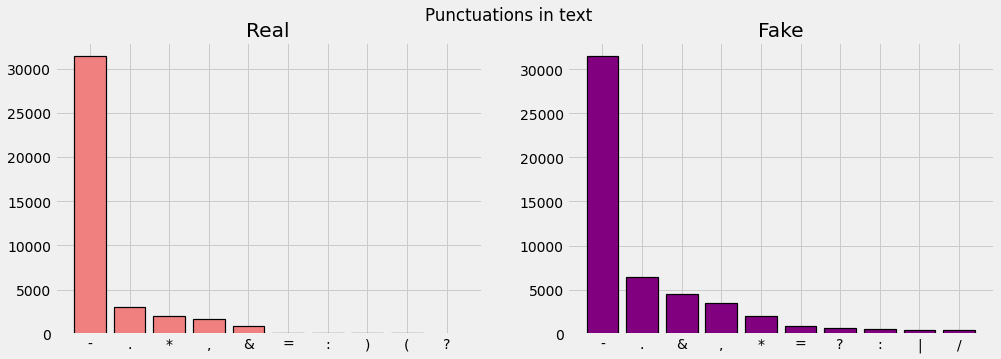

In [30]:
import string
# create a list with punctuation symbols
punctuation_list=list(string.punctuation)
value_list=[]
# define a function counts most occuring punct. symbols 
# according to the target class 
# with arguments: dataframe, function_form_words_list, list_of_targets
def most_occuring(dataset,fun,target):
 d=defaultdict(int)
 for j in range(0,len(target)): # for every type of target
  words=fun(target[j]) # call function create_words()
  for i in words: 
   if i in punctuation_list: # if word is punctuation symbol 
    d[i]+=1 # count it
  # sort to 10 symbols by their count in descending order
  top=sorted(d.items(),key=lambda x: x[1],reverse=True)[:10]
  # separate punctuation symbols from their quantification
  x_items,y_counts=zip(*top)
  # append symbols and their quantification to value_list
  value_list.append(x_items)
  value_list.append(y_counts)
 fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))
 
 ax1.bar(value_list[0],value_list[1],color="lightcoral",
 edgecolor='black', linewidth=1.2)
 ax1.set_title("Real")
 
 ax2.bar(value_list[2],value_list[3],color="purple",
 edgecolor='black', linewidth=1.2)
 ax2.set_title("Fake")
 
 plt.suptitle("Punctuations in text")
 plt.show()
most_occuring(df,create_words,[1,0])

Task 1 What is the difference between the object dict and defaultdict?


the main different between object dict and defaultdict is that when you try to access or modify a key that’s not present in the dictionary, a default value is automatically given to that key . 




In [32]:
#dict
testd = {}
testd #empty dict

{}

In [34]:
# if we try to call not defined key, we will have an error
testd['a']

KeyError: ignored

In [33]:
#defaultdict
testa = defaultdict(int) #there are could be used the other types not only int
testa #empty

defaultdict(int, {})

In [35]:
# if we try to call not defined key, there are will be created a new this key with default value type element
testa['a'] 

0

In [36]:
testa # not empty

defaultdict(int, {'a': 0})

In [38]:
#try to set the default value as concrete element
testa.default_factory = 13


In [39]:
testa['b'] #we have an error, because it's not callable

TypeError: ignored

In [40]:
#try to set the default value as function
testa.default_factory = lambda: 12


In [43]:
testa['b'] #we don't have an error, because it's callable


12

In [44]:
testa

defaultdict(<function __main__.<lambda>>, {'a': 0, 'b': 12})

Task 2 Why do we need to explore punctuation in text?


To express emotion in your text messages

In [24]:
#print the stop words
import nltk
from nltk.corpus import stopwords
print (stopwords.words('english'))


['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

In [25]:
import re
import string
from nltk.corpus import stopwords

def clean_text(text):
 lemmatizer = WordNetLemmatizer()
 stopwords_english = stopwords.words('english')
 text= re.sub('\[[^]]*\]', '', text)
 # remove stock market tickers like $GE
 text = re.sub(r'\$\w*', '', text)
 #removal of html tags
 review =re.sub(r'<.*?>',' ',text)
 # remove old style retweet text "RT"
 text = re.sub(r'^RT[\s]+', '', text)
 # remove hyperlinks
 text = re.sub(r'https?:\/\/.*[\r\n]*', '', text)
 # remove hashtags
 # only removing the hash # sign from the word
 text = re.sub(r'#', '', text)
 text = re.sub("["
              u"\U0001F600-\U0001F64F" # removal of emoticons
              u"\U0001F300-\U0001F5FF" # symbols & pictographs
              u"\U0001F680-\U0001F6FF" # transport & map symbols
              u"\U0001F1E0-\U0001F1FF" # flags (iOS)
              u"\U00002702-\U000027B0"
              u"\U000024C2-\U0001F251"
              "]+",' ',text)
 text = re.sub('[^a-zA-Z]',' ',text)
 text = text.lower()
 text_tokens =word_tokenize(text)

 text_clean = []
 for word in text_tokens:
  if (word not in stopwords_english and # remove stopwords
    word not in string.punctuation): # remove punctuation
      lem_word =lemmatizer.lemmatize(word) # lemmitiging word
      
      text_clean.append(lem_word)
 text_mod=[i for i in text_clean if len(i)>2]
 text_clean=' '.join(text_mod)
 return text_clean


In [26]:
df['clean_text']=df['text'].apply(lambda x: clean_text(x))


In [27]:
df['clean_temp']=df['clean_text'].apply(lambda x: str(x).split())
top=Counter([word for li in df['clean_temp'] for word in li])
temp_2=pd.DataFrame(top.most_common(20))
temp_2.columns=["common_words",'frequency']
temp_2.style.background_gradient(cmap='Blues')


,common_words,frequency
0,trump,142609
1,said,131174
2,state,61511
3,president,56889
4,would,54309
5,year,41475
6,people,40894
7,republican,40778
8,one,38265
9,new,32225


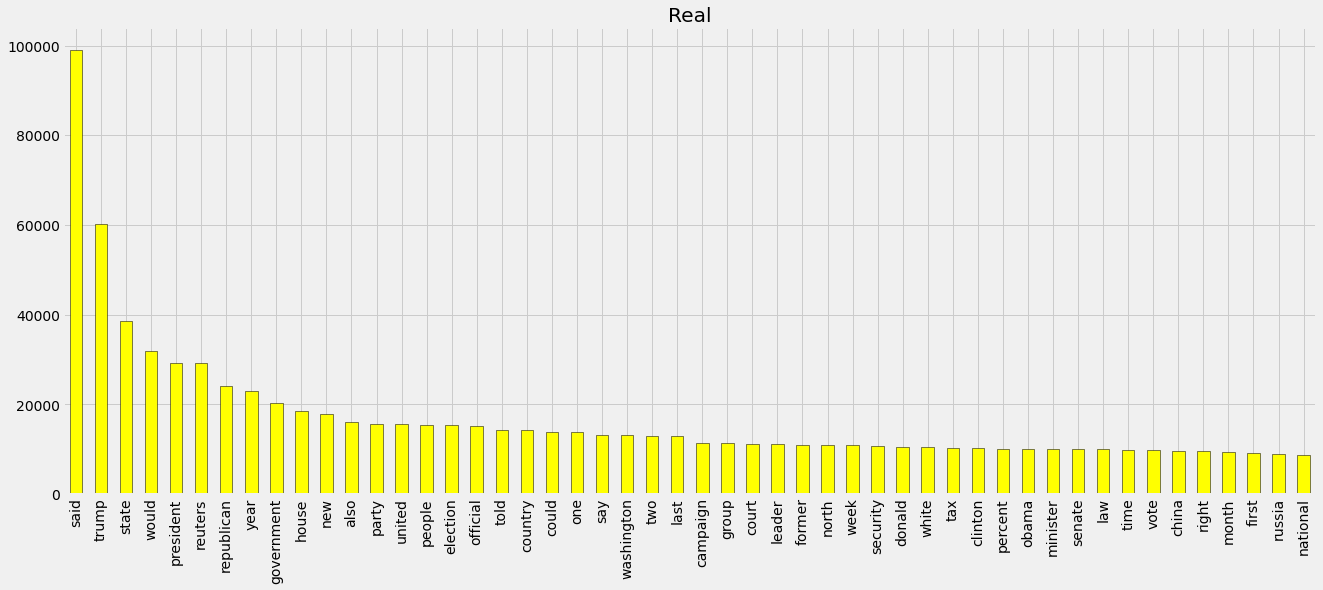

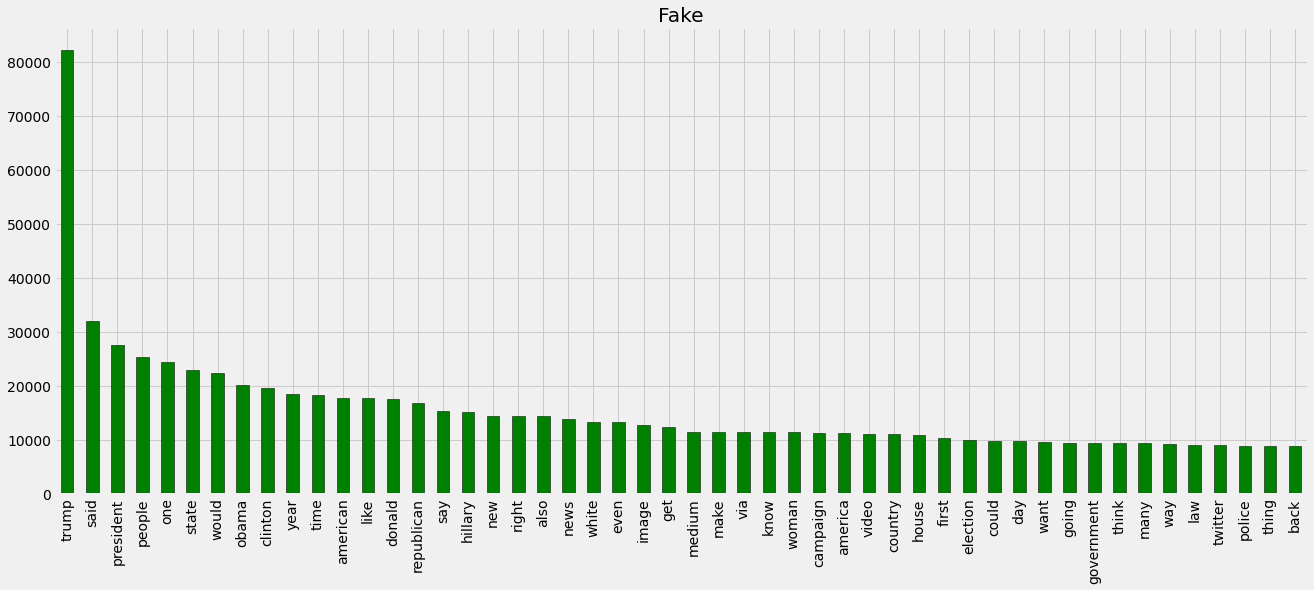

In [28]:
data_1=df[df['target']==1]
pd.Series(' '.join([i for i in
data_1.clean_text]).split()).value_counts()[:50].plot(kind='bar',figsize=(20,8),color='yellow'
,edgecolor='black',title='Real')
plt.show()
data_0=df[df['target']==0]
pd.Series(' '.join([i for i in
data_0.clean_text]).split()).value_counts()[:50].plot(kind='bar',figsize=(20,8),color='green' 
,edgecolor='black',title='Fake')

Task 3  Output top 50 most frequently occurring words after stemming (PorterStemmer) without stopwords punctuation symbols etc. for real and fake news separately.



asd

In [60]:
#true
data_11=df[df['target']==1]
data_11['clean_temp']=data_11['clean_text'].apply(lambda x: str(x).split())
top=Counter([word for li in data_11['clean_temp'] for word in li])
temp_3=pd.DataFrame(top.most_common(50))
temp_3.columns=["common_words",'frequency']
temp_3.style.background_gradient(cmap='YlOrRd')

,common_words,frequency
0,said,99076
1,trump,60297
2,state,38498
3,would,31839
4,president,29259
5,reuters,29109
6,republican,23982
7,year,22873
8,government,20412
9,house,18481


In [61]:
#fake
data_00=df[df['target']==0]
data_00['clean_temp']=data_00['clean_text'].apply(lambda x: str(x).split())
top=Counter([word for li in data_00['clean_temp'] for word in li])
temp_4=pd.DataFrame(top.most_common(50))
temp_4.columns=["common_words",'frequency']
temp_4.style.background_gradient(cmap='BuGn')

,common_words,frequency
0,trump,82312
1,said,32098
2,president,27630
3,people,25433
4,one,24393
5,state,23013
6,would,22470
7,obama,20156
8,clinton,19643
9,year,18602


Task 4 Plot the results with plotly. Analyze the results

In [66]:
import plotly.express as pe
import plotly.figure_factory as ff
fig = pe.bar(temp_3, x="frequency", y="common_words",
title='Commmon Words in True', orientation='h',
 width=700, height=700, color='common_words')
fig.show()

In [69]:
import plotly.express as pe
import plotly.figure_factory as ff
fig = pe.bar(temp_4, x="frequency", y="common_words",
title='Commmon Words in Fake', orientation='h',
 width=700, height=700, color='common_words')
fig.show()

Task 5 Describe the difference between stemming and lemmatization. List the advantages and disadvantages of both methods.


Stemming just removes or stems the last few characters of a word, often leading to incorrect meanings and spelling. Lemmatization considers the context and converts the word to its meaningful base form, which is called Lemma.



In [74]:
from nltk.stem import PorterStemmer

def stem_text(text):
 ps = PorterStemmer()
 stopwords_english = stopwords.words('english')
 text= re.sub('\[[^]]*\]', '', text)
 # remove stock market tickers like $GE
 text = re.sub(r'\$\w*', '', text)
 #removal of html tags
 review =re.sub(r'<.*?>',' ',text)
 # remove old style retweet text "RT"
 text = re.sub(r'^RT[\s]+', '', text)
 # remove hyperlinks
 text = re.sub(r'https?:\/\/.*[\r\n]*', '', text)
 # remove hashtags
 # only removing the hash # sign from the word
 text = re.sub(r'#', '', text)
 text = re.sub("["
              u"\U0001F600-\U0001F64F" # removal of emoticons
              u"\U0001F300-\U0001F5FF" # symbols & pictographs
              u"\U0001F680-\U0001F6FF" # transport & map symbols
              u"\U0001F1E0-\U0001F1FF" # flags (iOS)
              u"\U00002702-\U000027B0"
              u"\U000024C2-\U0001F251"
              "]+",' ',text)
 text = re.sub('[^a-zA-Z]',' ',text)
 text = text.lower()
 text_tokens =word_tokenize(text)

 text_clean = []
 for word in text_tokens:
  if (word not in stopwords_english and # remove stopwords
    word not in string.punctuation): # remove punctuation
      stem_word =ps.stem(word) # stemming word
      
      text_clean.append(stem_word)
 text_mod=[i for i in text_clean if len(i)>2]
 text_clean=' '.join(text_mod)
 return text_clean

In [75]:
df['clean_text']=df['text'].apply(lambda x: stem_text(x))


In [76]:
#true
data_111=df[df['target']==1]
data_111['clean_temp']=data_11['clean_text'].apply(lambda x: str(x).split())
top=Counter([word for li in data_11['clean_temp'] for word in li])
temp_5=pd.DataFrame(top.most_common(50))
temp_5.columns=["common_words",'frequency']
temp_5.style.background_gradient(cmap='YlOrRd')

,common_words,frequency
0,said,99076
1,trump,60297
2,state,38498
3,would,31839
4,president,29259
5,reuters,29109
6,republican,23982
7,year,22873
8,government,20412
9,house,18481


In [77]:
#fake
data_000=df[df['target']==0]
data_000['clean_temp']=data_00['clean_text'].apply(lambda x: str(x).split())
top=Counter([word for li in data_00['clean_temp'] for word in li])
temp_6=pd.DataFrame(top.most_common(50))
temp_6.columns=["common_words",'frequency']
temp_6.style.background_gradient(cmap='BuGn')

,common_words,frequency
0,trump,82312
1,said,32098
2,president,27630
3,people,25433
4,one,24393
5,state,23013
6,would,22470
7,obama,20156
8,clinton,19643
9,year,18602


In [78]:
fig = pe.bar(temp_5, x="frequency", y="common_words",
title='Commmon Words in True', orientation='h',
 width=700, height=700, color='common_words')
fig.show()

In [79]:
fig = pe.bar(temp_6, x="frequency", y="common_words",
title='Commmon Words in True', orientation='h',
 width=700, height=700, color='common_words')
fig.show()